# 01 — Data Audit
**Project:** Planetary Defense Analytics  
**Goal:** Understand the raw NASA SBDB export *before* touching it: shape, dtypes, missingness, duplicates, invalid values, target balance, and leakage risks.  
**Rule:** This notebook only *reads* `data/raw/`. It never modifies it.

## 1. Setup & paths

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
sns.set_theme(style="whitegrid")

# Works whether Jupyter starts in project root or in notebooks/
ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent

RAW_DIR = ROOT / "data" / "raw"
FIG_DIR = ROOT / "reports" / "figures"
RES_DIR = ROOT / "reports" / "results"
for d in (RAW_DIR, FIG_DIR, RES_DIR):
    d.mkdir(parents=True, exist_ok=True)

csvs = sorted(RAW_DIR.glob("*.csv"))
if not csvs:
    raise FileNotFoundError(f"No CSV found in {RAW_DIR}. Copy the dataset there first.")
RAW_FILE = csvs[0]
print("ROOT     :", ROOT)
print("Raw file :", RAW_FILE.name, f"({RAW_FILE.stat().st_size/1e6:.1f} MB)")

ROOT     : c:\Projects\Planetary_Defense_Analytics
Raw file : pha_dataset.csv (458.6 MB)


## 2. Load

In [2]:
df = pd.read_csv(RAW_FILE, low_memory=False)
print("Shape:", df.shape)
print("Expected (from brief): (958524, 45)  ->", "MATCH" if df.shape == (958524, 45) else "DIFFERENT, check file")
df.head()

Shape: (958524, 45)
Expected (from brief): (958524, 45)  -> MATCH


,id,spkid,full_name,pdes,name,prefix,neo,pha,H,diameter,albedo,diameter_sigma,orbit_id,epoch,epoch_mjd,epoch_cal,equinox,e,a,q,i,om,w,ma,ad,n,tp,tp_cal,per,per_y,moid,moid_ld,sigma_e,sigma_a,sigma_q,sigma_i,sigma_om,sigma_w,sigma_ma,sigma_ad,sigma_n,sigma_tp,sigma_per,class,rms
0,a0000001,2000001,1 Ceres,1,Ceres,NaN,N,N,3.40,939.400,0.0900,0.200,JPL 47,2458600.5,58600,20190427.0,J2000,0.076009,2.769165,2.558684,10.594067,80.305531,73.597695,77.372098,2.979647,0.213885,2.458239e+06,2.018043e+07,1683.145703,4.608202,1.59478,620.640533,4.819000e-12,1.032800e-11,1.956900e-11,4.608900e-09,6.168800e-08,6.624800e-08,7.820700e-09,1.111300e-11,1.196500e-12,3.782900e-08,9.415900e-09,MBA,0.43301
1,a0000002,2000002,2 Pallas,2,Pallas,NaN,N,N,4.20,545.000,0.1010,18.000,JPL 37,2459000.5,59000,20200531.0,J2000,0.229972,2.773841,2.135935,34.832932,173.024741,310.202392,144.975675,3.411748,0.213345,2.458321e+06,2.018072e+07,1687.410992,4.619880,1.23429,480.348639,3.193400e-08,4.033700e-09,8.832200e-08,3.469400e-06,6.272400e-06,9.128200e-06,8.859100e-06,4.961300e-09,4.653600e-10,4.078700e-05,3.680700e-06,MBA,0.35936
2,a0000003,2000003,3 Juno,3,Juno,NaN,N,N,5.33,246.596,0.2140,10.594,JPL 112,2459000.5,59000,20200531.0,J2000,0.256936,2.668285,1.982706,12.991043,169.851482,248.066193,125.435355,3.353865,0.226129,2.458446e+06,2.018112e+07,1592.013769,4.358696,1.03429,402.514639,3.052000e-08,3.471800e-09,8.139200e-08,3.223100e-06,1.664600e-05,1.772100e-05,8.110400e-06,4.363900e-09,4.413400e-10,3.528800e-05,3.107200e-06,MBA,0.33848
3,a0000004,2000004,4 Vesta,4,Vesta,NaN,N,N,3.00,525.400,0.4228,0.200,JPL 35,2458600.5,58600,20190427.0,J2000,0.088721,2.361418,2.151909,7.141771,103.810804,150.728541,95.861938,2.570926,0.271609,2.458248e+06,2.018051e+07,1325.432763,3.628837,1.13948,443.451432,2.332100e-10,1.514300e-09,1.928600e-09,2.170600e-07,3.880800e-07,1.789300e-07,1.206800e-06,1.648600e-09,2.612500e-10,4.103700e-06,1.274900e-06,MBA,0.39980
4,a0000005,2000005,5 Astraea,5,Astraea,NaN,N,N,6.90,106.699,0.2740,3.140,JPL 114,2459000.5,59000,20200531.0,J2000,0.190913,2.574037,2.082619,5.367427,141.571026,358.648418,17.846343,3.065455,0.238661,2.458926e+06,2.020032e+07,1508.414421,4.129814,1.09575,426.433027,2.373700e-08,3.970900e-09,6.092400e-08,2.740800e-06,2.894900e-05,2.984200e-05,8.303800e-06,4.729000e-09,5.522700e-10,3.474300e-05,3.490500e-06,MBA,0.52191


## 3. Structure: dtypes & memory

In [3]:
info = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "non_null": df.notna().sum(),
    "n_unique": df.nunique(),
})
info["missing_%"] = (df.isna().mean() * 100).round(2)
print(f"Memory: {df.memory_usage(deep=True).sum()/1e6:.1f} MB")
info

Memory: 391.4 MB


,dtype,non_null,n_unique,missing_%
id,str,958524,958524,0.00
spkid,int64,958524,958524,0.00
full_name,str,958524,958524,0.00
pdes,str,958524,958524,0.00
name,str,22064,22064,97.70
prefix,str,18,1,100.00
neo,str,958520,2,0.00
pha,str,938603,2,2.08
H,float64,952261,9489,0.65
diameter,float64,136209,16591,85.79


## 4. Summary statistics

In [4]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
spkid,958524.0,3.810114e+06,6.831541e+06,2.000001e+06,2.239632e+06,2.479262e+06,3.752518e+06,5.401723e+07
H,952261.0,1.690641e+01,1.790405e+00,-1.100000e+00,1.610000e+01,1.690000e+01,1.771400e+01,3.320000e+01
diameter,136209.0,5.506429e+00,9.425164e+00,2.500000e-03,2.780000e+00,3.972000e+00,5.765000e+00,9.394000e+02
albedo,135103.0,1.306272e-01,1.103228e-01,1.000000e-03,5.300000e-02,7.900000e-02,1.900000e-01,1.000000e+00
diameter_sigma,136081.0,4.791844e-01,7.828952e-01,5.000000e-04,1.800000e-01,3.320000e-01,6.200000e-01,1.400000e+02
epoch,958524.0,2.458869e+06,7.016716e+02,2.425052e+06,2.459000e+06,2.459000e+06,2.459000e+06,2.459000e+06
epoch_mjd,958524.0,5.886878e+04,7.016716e+02,2.505100e+04,5.900000e+04,5.900000e+04,5.900000e+04,5.900000e+04
epoch_cal,958524.0,2.019693e+07,1.930354e+04,1.927062e+07,2.020053e+07,2.020053e+07,2.020053e+07,2.020053e+07
e,958524.0,1.561163e-01,9.264264e-02,0.000000e+00,9.219296e-02,1.450017e-01,2.006503e-01,1.855356e+00
a,958524.0,2.902143e+00,3.971950e+01,-1.470245e+04,2.387835e+00,2.646969e+00,3.001932e+00,3.348890e+04


In [5]:
cat_cols = df.select_dtypes(include="object").columns.tolist()
df[cat_cols].describe().T

,count,unique,top,freq
id,958524,958524,a0000001,1
full_name,958524,958524,1 Ceres,1
pdes,958524,958524,1,1
name,22064,22064,Ceres,1
prefix,18,1,A,18
neo,958520,2,N,935625
pha,938603,2,N,936537
orbit_id,958524,4690,1,50142
equinox,958524,1,J2000,958524
class,958524,13,MBA,855954


## 5. Missing values

,missing_%
prefix,100.00
name,97.70
albedo,85.91
diameter_sigma,85.80
diameter,85.79
sigma_per,2.08
sigma_ad,2.08
sigma_om,2.08
sigma_ma,2.08
sigma_q,2.08


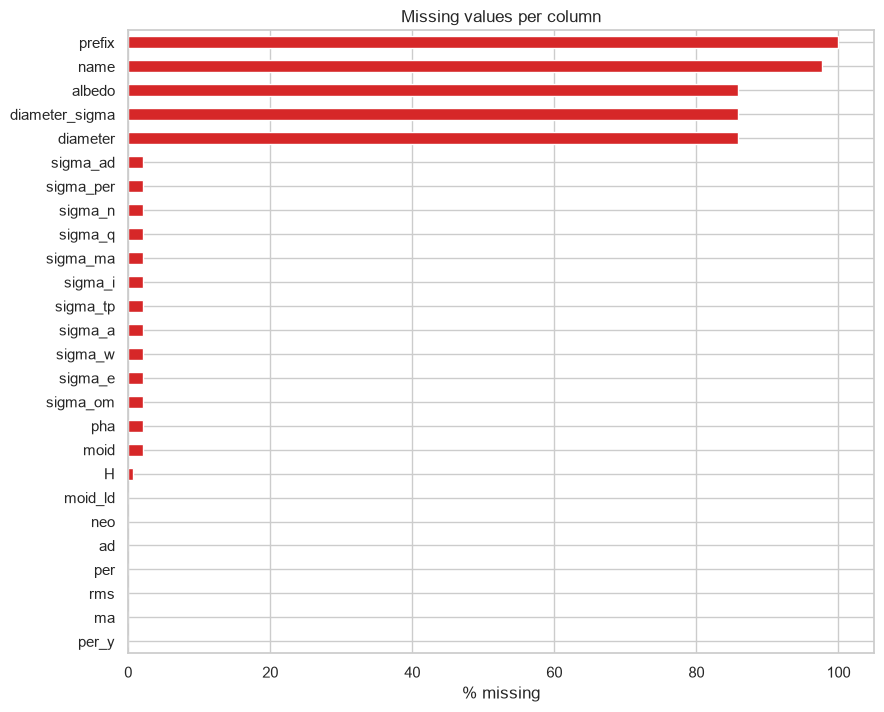

In [6]:
miss = (df.isna().mean() * 100).sort_values(ascending=False)
miss = miss[miss > 0]
display(miss.round(2).to_frame("missing_%"))

fig, ax = plt.subplots(figsize=(9, max(4, 0.28 * len(miss))))
miss.sort_values().plot.barh(ax=ax, color="tab:red")
ax.set_xlabel("% missing"); ax.set_title("Missing values per column")
plt.tight_layout(); plt.savefig(FIG_DIR / "01_missing_values.png", dpi=150); plt.show()

## 6. Duplicates

In [7]:
print("Fully duplicated rows :", df.duplicated().sum())
for c in ["id", "spkid", "pdes", "full_name"]:
    if c in df.columns:
        print(f"Duplicate {c:10s}:", df[c].dropna().duplicated().sum())

Fully duplicated rows : 0
Duplicate id        : 0
Duplicate spkid     : 0
Duplicate pdes      : 0
Duplicate full_name : 0


## 7. Column roles
Classify every column *before* modelling. Adjust the lists below if your file has different columns.

In [8]:
roles = {
    "identifier":  ["id", "spkid", "full_name", "pdes", "name", "prefix"],
    "orbital":     ["a", "e", "i", "om", "w", "ma", "q", "ad", "n", "tp", "per", "per_y"],
    "physical":    ["H", "diameter", "albedo", "diameter_sigma", "extent", "GM", "rot_per", "BV", "UB", "IR", "spec_B", "spec_T"],
    "proximity":   ["moid", "moid_ld", "moid_jup"],
    "label_flags": ["neo", "pha", "class"],
    "quality":     ["epoch", "epoch_mjd", "epoch_cal", "equinox", "orbit_id", "condition_code",
                    "data_arc", "n_obs_used", "first_obs", "last_obs", "producer", "sigma_e", "sigma_a",
                    "sigma_q", "sigma_i", "sigma_om", "sigma_w", "sigma_ma", "sigma_ad", "sigma_n",
                    "sigma_tp", "sigma_per", "t_jup", "kind"],
}
assigned = set()
rows = []
for role, cols in roles.items():
    present = [c for c in cols if c in df.columns]
    assigned.update(present)
    rows.append((role, len(present), present))
unassigned = [c for c in df.columns if c not in assigned]
rows.append(("UNASSIGNED", len(unassigned), unassigned))
pd.DataFrame(rows, columns=["role", "count", "columns"])

,role,count,columns
0,identifier,6,"[id, spkid, full_name, pdes, name, prefix]"
1,orbital,12,"[a, e, i, om, w, ma, q, ad, n, tp, per, per_y]"
2,physical,4,"[H, diameter, albedo, diameter_sigma]"
3,proximity,2,"[moid, moid_ld]"
4,label_flags,3,"[neo, pha, class]"
5,quality,16,"[epoch, epoch_mjd, epoch_cal, equinox, orbit_i..."
6,UNASSIGNED,2,"[tp_cal, rms]"


## 8. Target audit — `pha`, `neo`, `class`

--- pha ---
      count       %
pha                
N    936537  97.706
NaN   19921   2.078
Y      2066   0.216 

--- neo ---
      count       %
neo                
N    935625  97.611
Y     22895   2.389
NaN       4   0.000 

PHA imbalance (labelled rows only): 2,066 Y vs 936,537 N  ->  1 : 453
Rows with pha missing: 19,921 (cannot be used for Case 1 training)


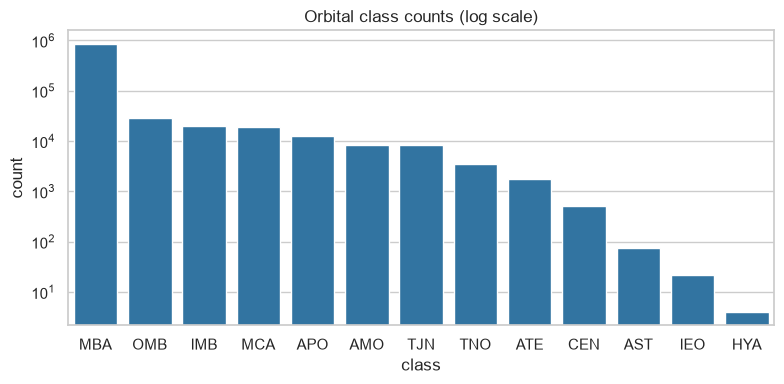

,count
class,
MBA,855954
OMB,28355
IMB,20360
MCA,18685
APO,12687
AMO,8457
TJN,8221
TNO,3468
ATE,1729


In [9]:
for c in ["pha", "neo"]:
    if c in df.columns:
        vc = df[c].value_counts(dropna=False)
        print(f"--- {c} ---")
        print(pd.DataFrame({"count": vc, "%": (vc / len(df) * 100).round(3)}), "\n")

if "pha" in df.columns:
    known = df["pha"].dropna()
    pos = (known == "Y").sum(); neg = (known == "N").sum()
    print(f"PHA imbalance (labelled rows only): {pos:,} Y vs {neg:,} N  ->  1 : {neg/max(pos,1):,.0f}")
    print(f"Rows with pha missing: {df['pha'].isna().sum():,} (cannot be used for Case 1 training)")

if "class" in df.columns:
    vc = df["class"].value_counts()
    fig, ax = plt.subplots(figsize=(8, 4))
    sns.barplot(x=vc.index, y=vc.values, ax=ax, color="tab:blue")
    ax.set_yscale("log"); ax.set_title("Orbital class counts (log scale)"); ax.set_ylabel("count")
    plt.tight_layout(); plt.savefig(FIG_DIR / "01_class_counts.png", dpi=150); plt.show()
    display(vc.to_frame("count"))

## 9. Invalid / physically impossible values

In [10]:
checks = {}
def add(name, mask): checks[name] = int(mask.sum())

if "e" in df:        add("e < 0", df["e"] < 0); add("e >= 1 (hyperbolic/parabolic)", df["e"] >= 1)
if "a" in df:        add("a <= 0", df["a"] <= 0)
if {"a","e"} <= set(df): add("a < 0 while e < 1", (df["a"] < 0) & (df["e"] < 1))
if "q" in df:        add("q <= 0", df["q"] <= 0)
if "i" in df:        add("i outside [0, 180]", ~df["i"].between(0, 180) & df["i"].notna())
for ang in ["om", "w", "ma"]:
    if ang in df:    add(f"{ang} outside [0, 360]", ~df[ang].between(0, 360) & df[ang].notna())
if "H" in df:        add("H < 0 or H > 35", ~df["H"].between(0, 35) & df["H"].notna())
if "diameter" in df: add("diameter <= 0", df["diameter"] <= 0)
if "albedo" in df:   add("albedo outside [0, 1]", ~df["albedo"].between(0, 1) & df["albedo"].notna())
if "moid" in df:     add("moid < 0", df["moid"] < 0)
if "n_obs_used" in df: add("n_obs_used <= 0", df["n_obs_used"] <= 0)

pd.Series(checks, name="violations").to_frame()

,violations
e < 0,0
e >= 1 (hyperbolic/parabolic),4
a <= 0,4
a < 0 while e < 1,0
q <= 0,0
"i outside [0, 180]",0
"om outside [0, 360]",0
"w outside [0, 360]",0
"ma outside [0, 360]",95
H < 0 or H > 35,3


## 10. Leakage check — is `pha` just a formula?
By definition **PHA = (moid ≤ 0.05 AU) AND (H ≤ 22.0)**. If we can reproduce the label from those two columns, then including `moid` and `H` makes Case 1 trivial (and useless).

In [11]:
if {"pha", "moid", "H"} <= set(df.columns):
    sub = df.dropna(subset=["pha", "moid", "H"]).copy()
    sub["pha_rule"] = np.where((sub["moid"] <= 0.05) & (sub["H"] <= 22.0), "Y", "N")
    agree = (sub["pha_rule"] == sub["pha"]).mean() * 100
    print(f"Rows tested: {len(sub):,}")
    print(f"Rule reproduces pha label on {agree:.4f}% of rows\n")
    print(pd.crosstab(sub["pha"], sub["pha_rule"], rownames=["actual"], colnames=["rule"]))

Rows tested: 932,341
Rule reproduces pha label on 99.9940% of rows

rule         N     Y
actual              
N       930238    37
Y           19  2047


### Near-duplicate / derived features (multicollinearity preview)

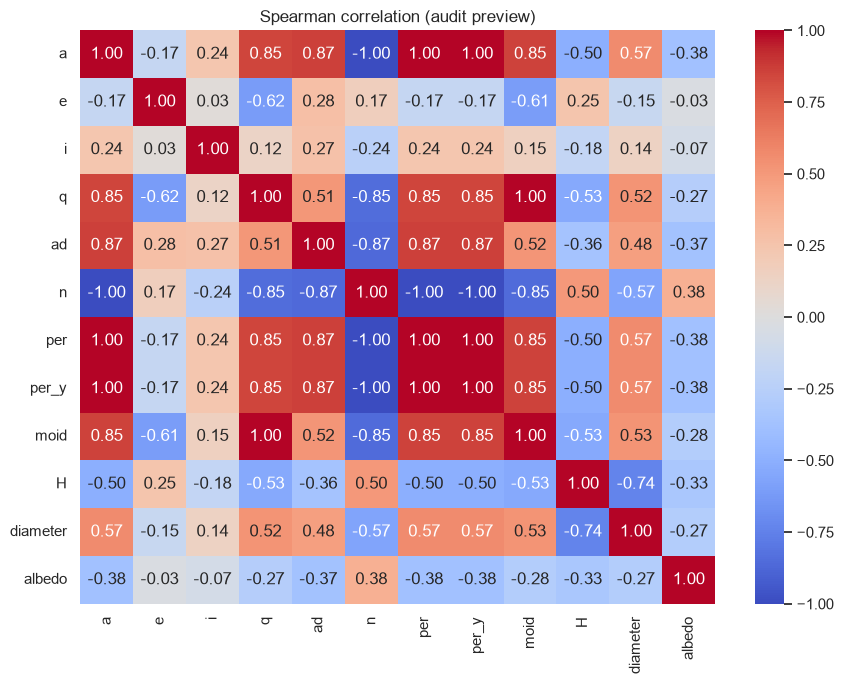

max |ad - a(1+e)|  : 4.9991220052447716e-08
max |q  - a(1-e)|  : 4.9991219608358506e-08
max |per_y - a^1.5|: 115.74567064736038  (Kepler's 3rd law)


In [12]:
orb = [c for c in ["a","e","i","q","ad","n","per","per_y","moid","H","diameter","albedo"] if c in df.columns]
corr = df[orb].corr(method="spearman")
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax)
ax.set_title("Spearman correlation (audit preview)")
plt.tight_layout(); plt.savefig(FIG_DIR / "01_corr_preview.png", dpi=150); plt.show()

# Exact derived relations
if {"a","e","ad"} <= set(df):
    d = (df["ad"] - df["a"]*(1+df["e"])).abs().dropna()
    print("max |ad - a(1+e)|  :", d.max())
if {"a","e","q"} <= set(df):
    d = (df["q"] - df["a"]*(1-df["e"])).abs().dropna()
    print("max |q  - a(1-e)|  :", d.max())
if {"a","per_y"} <= set(df):
    ok = df.dropna(subset=["a","per_y"]); ok = ok[ok["a"] > 0]
    d = (ok["per_y"] - ok["a"]**1.5).abs()
    print("max |per_y - a^1.5|:", d.max(), " (Kepler's 3rd law)")

## 11. Diameter (Case 2 target) availability
`diameter` is measured only for a small subset. Regression trains **only** on rows where it exists.

Rows with diameter: 136,209 (14.21%)
count    136209.0000
mean          5.5064
std           9.4252
min           0.0025
25%           2.7800
50%           3.9720
75%           5.7650
max         939.4000

Skew: 25.85
Rows with diameter + H + albedo: 131,237


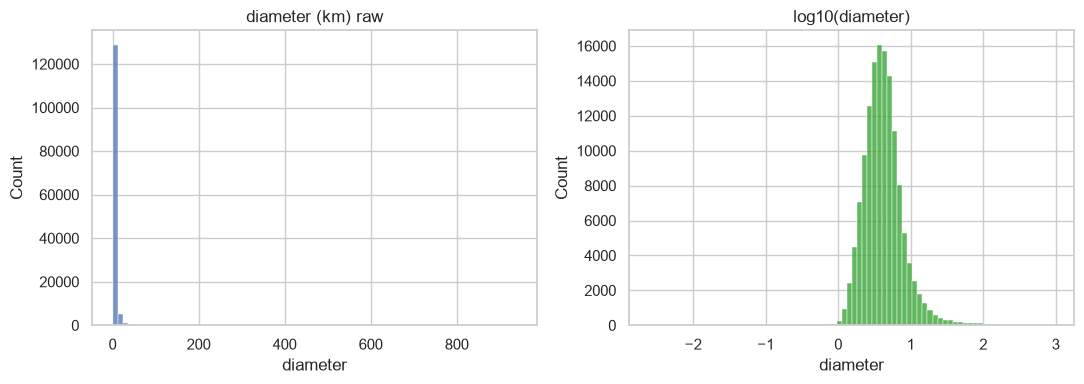

In [13]:
if "diameter" in df:
    d = df["diameter"].dropna()
    print(f"Rows with diameter: {len(d):,} ({len(d)/len(df)*100:.2f}%)")
    print(d.describe().round(4).to_string())
    print("\nSkew:", round(d.skew(), 2))
    if {"H", "albedo"} <= set(df):
        both = df.dropna(subset=["diameter", "H", "albedo"])
        print(f"Rows with diameter + H + albedo: {len(both):,}")

    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    sns.histplot(d, bins=80, ax=axes[0]); axes[0].set_title("diameter (km) raw")
    sns.histplot(np.log10(d[d > 0]), bins=80, ax=axes[1], color="tab:green"); axes[1].set_title("log10(diameter)")
    plt.tight_layout(); plt.savefig(FIG_DIR / "01_diameter_dist.png", dpi=150); plt.show()

## 12. Usable rows per case

In [14]:
summary = {"total_rows": len(df)}
if "pha" in df:
    summary["case1_usable (pha labelled)"] = int(df["pha"].notna().sum())
    summary["case1_pha_Y"] = int((df["pha"] == "Y").sum())
if "diameter" in df:
    summary["case2_usable (diameter present)"] = int(df["diameter"].notna().sum())
orb_cols = [c for c in ["a","e","i","om","w","ma"] if c in df]
summary["case3_usable (orbital complete)"] = int(df[orb_cols].notna().all(axis=1).sum())
summary_df = pd.Series(summary, name="rows").to_frame()
summary_df

,rows
total_rows,958524
case1_usable (pha labelled),938603
case1_pha_Y,2066
case2_usable (diameter present),136209
case3_usable (orbital complete),958523


## 13. Save audit outputs

In [15]:
info.to_csv(RES_DIR / "01_column_audit.csv")
summary_df.to_csv(RES_DIR / "01_usable_rows.csv")
pd.Series(checks, name="violations").to_csv(RES_DIR / "01_invalid_values.csv")
print("Saved to", RES_DIR)

Saved to c:\Projects\Planetary_Defense_Analytics\reports\results
